AVENUE 29-B (v11): CLOSURE OF PENDING PREDICTIONS

[1] PER-EVENT MEMBRANE CLOSURE
  -> R_meas = 0.4773 (Target: 21/44 = 0.4773)
  -> T_meas = 0.5227 (Target: 23/44 = 0.5227)

[2] FINITE ECHO COUNT & EXACT MODULAR BUDGET (r <= probe_r)
  -> E0 + E_flight (Total Init)   = 7771.0
  -> E_retained (Final Locked)    = 684.5
  -> dE_total (Available to Leak) = 7086.5
  -> E_leaked_real (Probe Sum)    = 7086.5
  -> E_pkt_ring (Mean Ring Peak)  = 34.84
  -> N_pred_real (dE / E_pkt)     = 203.4
  -> N_meas (Detected Packets)    = 64

✓ Saved: avenue_29b_v11_closure.png


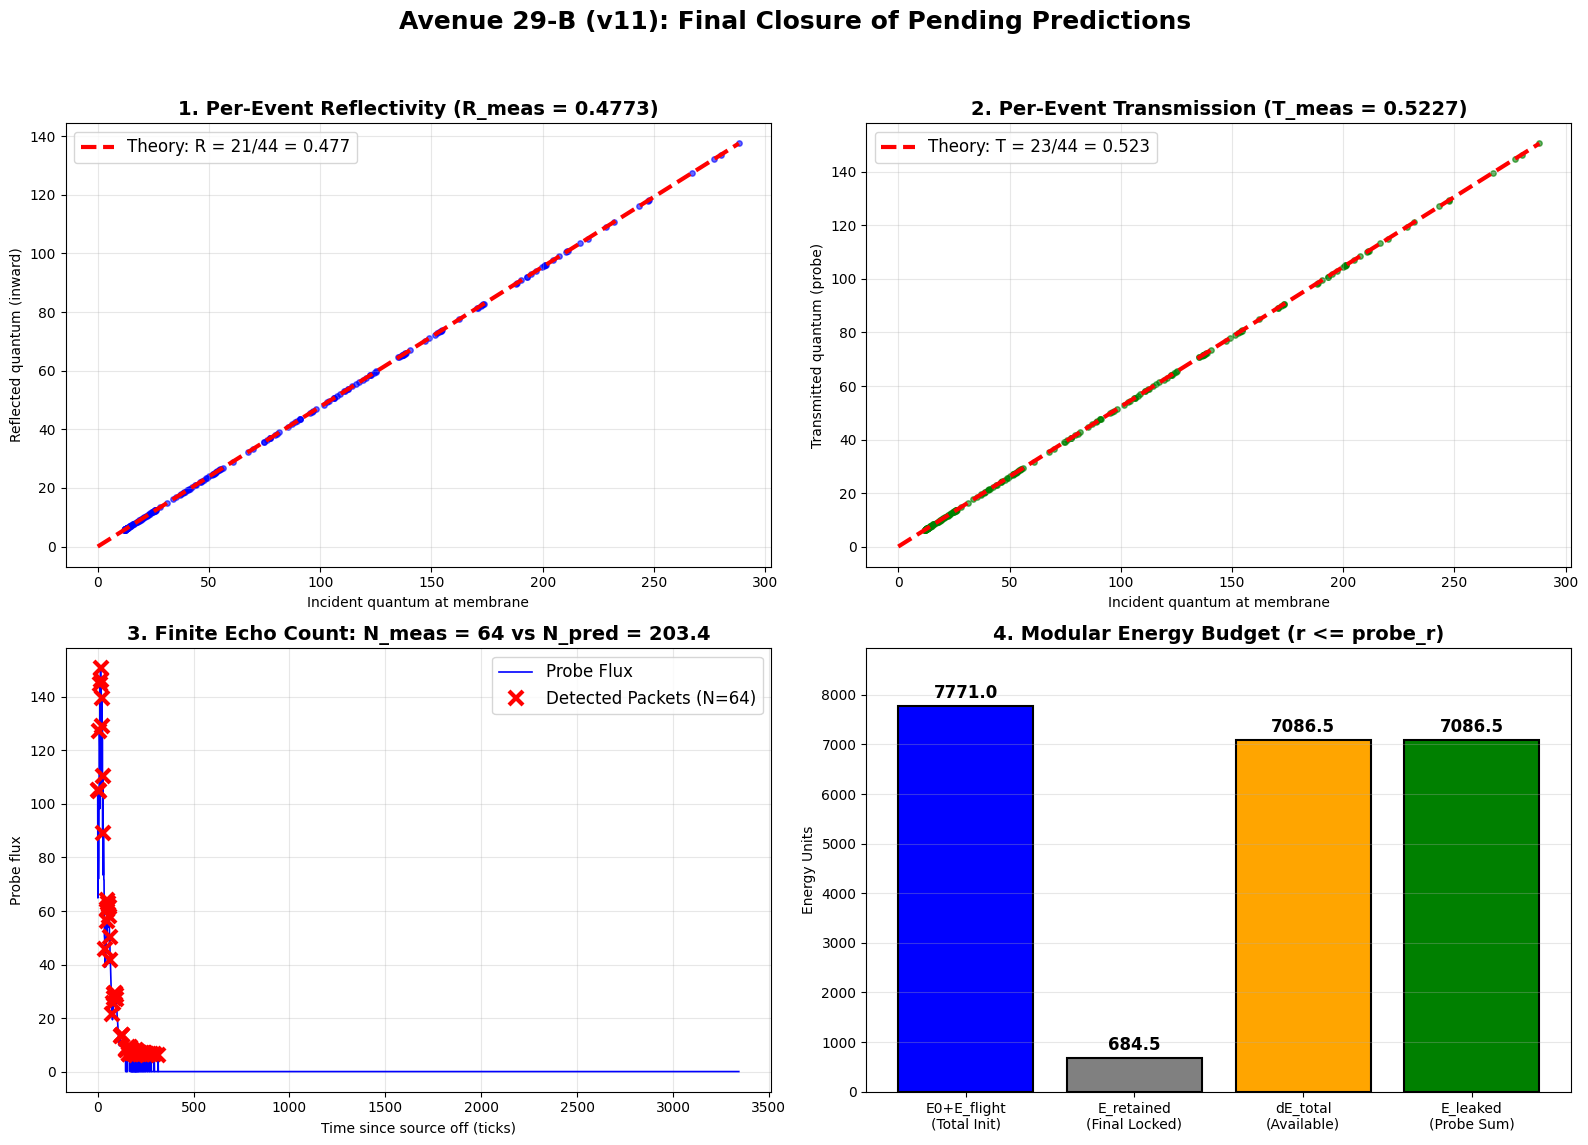

In [3]:
"""
avenue_29b_v11_closure.py
====================================================================
AVENUE 29-B (v11): CLOSURE OF PENDING PREDICTIONS
Converts Section 9 items 1-2 from pending to measured:
  1. Per-event membrane closure: R_meas = <ret>/<in> and T_meas = <probe>/<in>.
  2. Finite echo count & exact modular energy budget inside probe sphere.
====================================================================
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
import warnings
warnings.filterwarnings('ignore')

CAPACITY, SIGMA = 8.0, 40.0
TRB_THRESHOLD, TRB_MAX = 21, 44
R_DERIVED = 21.0 / 44.0

def run_v11(N_CELLS, SOURCE_FLUX, R, T_RING=3000, CAP=400):
    T_TOTAL = CAP + T_RING + 20
    r = np.arange(N_CELLS)
    profile = SOURCE_FLUX * np.exp(-(r / SIGMA) ** 2)
    r_h = SIGMA * np.sqrt(np.log(SOURCE_FLUX / CAPACITY))
    rh = int(r_h); probe_r = rh + 20

    trb = np.zeros(N_CELLS); locked = np.zeros(N_CELLS, dtype=bool)
    p_out = np.zeros((T_TOTAL + 50, N_CELLS)); p_in = np.zeros((T_TOTAL + 50, N_CELLS))
    rad_sched = np.zeros(T_TOTAL + 50)
    probe_sig = np.zeros(T_TOTAL)

    mem_events = []  # logs every membrane split
    formed = False; T_FORM = CAP; E0 = 0.0; E_flight = 0.0

    for t in range(T_TOTAL):
        if not formed:
            inner = trb[:max(3, rh)]
            steady = np.mean(inner >= TRB_THRESHOLD - 1e-9) >= 0.8
            if (steady and t >= 4 * r_h) or t >= CAP:
                formed = True; T_FORM = t
                # Exact control volume inside probe sphere (r <= probe_r)
                E0 = np.sum(trb[:probe_r + 1])
                E_flight = np.sum(p_out[t, :probe_r + 1]) + np.sum(p_in[t, :probe_r + 1])

        src = profile if not formed else np.zeros(N_CELLS)

        arr_o = p_out[t]; arr_i = p_in[t]
        probe_sig[t] = arr_o[probe_r] + arr_i[probe_r]

        processed = np.where(locked, 0.0, np.minimum(src, CAPACITY))
        processed[probe_r] = src[probe_r]
        trb += src - processed
        trb[0] += arr_i[0] + arr_o[0]
        trb[probe_r] = 0.0
        locked |= (~locked) & (trb >= TRB_THRESHOLD)
        locked[probe_r] = False
        trb_pre = trb.copy()

        # Horizon membrane
        mem = arr_o[rh]
        route_o = arr_o.copy()
        if mem > 1e-6:
            route_o[rh] = 0.0
            probe_mag = mem * (1 - R)
            ret_mag = mem * R
            mem_events.append({'t': t, 'in': mem, 'probe': probe_mag, 'ret': ret_mag})
            if rh + 1 < N_CELLS: p_out[t + 1, rh + 1] += probe_mag
            else: rad_sched[t + 1] += probe_mag
            p_in[t + 1, rh - 1] += ret_mag

        # Flips
        for rr in np.nonzero(trb_pre >= TRB_MAX)[0]:
            if rr == probe_r: continue
            mag_ej = trb_pre[rr] - TRB_THRESHOLD
            o = mag_ej * (1 - R)
            if rr + 1 < N_CELLS: p_out[t + 1, rr + 1] += o
            else: rad_sched[t + 1] += o
            trb[rr] = TRB_THRESHOLD + mag_ej * R
            locked[rr] = True

        # Transparent conduit
        route_o[0] = 0.0
        route_i = arr_i.copy(); route_i[0] = 0.0
        p_out[t + 1, 1:] += route_o[:-1]
        rad_sched[t + 1] += route_o[-1]
        p_in[t + 1, :-1] += route_i[1:]

    # Post-processing
    mem_events = {k: np.array([e[k] for e in mem_events]) for k in mem_events[0]} if mem_events else {}

    # Final retained energy inside probe sphere at end of ringdown
    E_retained = np.sum(trb[:probe_r + 1])

    # Count probe packets during ringdown
    ringdown_probe = probe_sig[T_FORM:]
    peaks, _ = find_peaks(ringdown_probe, height=0.5)
    N_meas = len(peaks)

    return dict(T_FORM=T_FORM, E0=E0, E_flight=E_flight, E_retained=E_retained,
                rh=rh, r_h=r_h, probe_r=probe_r, mem_events=mem_events,
                probe_sig=probe_sig, ringdown_probe=ringdown_probe,
                peaks=peaks, N_meas=N_meas)

print("=" * 80)
print("AVENUE 29-B (v11): CLOSURE OF PENDING PREDICTIONS")
print("=" * 80)

# Run
res = run_v11(150, 10.0, R_DERIVED)

# Calculate ratios
in_mags = res['mem_events']['in']
probe_mags = res['mem_events']['probe']
ret_mags = res['mem_events']['ret']

R_meas = np.mean(ret_mags) / np.mean(in_mags)
T_meas = np.mean(probe_mags) / np.mean(in_mags)

# Exact modular energy budget inside probe sphere (r <= probe_r)
E_total_init = res['E0'] + res['E_flight']
E_min = res['E_retained']
dE_total = E_total_init - E_min
ringdown_probe = res['ringdown_probe']
E_leaked_real = np.sum(ringdown_probe)
E_pkt_ring = np.mean(ringdown_probe[res['peaks']]) if res['N_meas'] > 0 else np.nan
N_pred_real = dE_total / E_pkt_ring

print(f"\n[1] PER-EVENT MEMBRANE CLOSURE")
print(f"  -> R_meas = {R_meas:.4f} (Target: 21/44 = {R_DERIVED:.4f})")
print(f"  -> T_meas = {T_meas:.4f} (Target: 23/44 = {1-R_DERIVED:.4f})")

print(f"\n[2] FINITE ECHO COUNT & EXACT MODULAR BUDGET (r <= probe_r)")
print(f"  -> E0 + E_flight (Total Init)   = {E_total_init:.1f}")
print(f"  -> E_retained (Final Locked)    = {E_min:.1f}")
print(f"  -> dE_total (Available to Leak) = {dE_total:.1f}")
print(f"  -> E_leaked_real (Probe Sum)    = {E_leaked_real:.1f}")
print(f"  -> E_pkt_ring (Mean Ring Peak)  = {E_pkt_ring:.2f}")
print(f"  -> N_pred_real (dE / E_pkt)     = {N_pred_real:.1f}")
print(f"  -> N_meas (Detected Packets)    = {res['N_meas']}")

# Plotting
fig = plt.figure(figsize=(16, 12))
fig.suptitle('Avenue 29-B (v11): Final Closure of Pending Predictions', fontsize=18, fontweight='bold')

# P1: R_meas scatter
ax1 = fig.add_subplot(2, 2, 1)
ax1.scatter(in_mags, ret_mags, s=15, alpha=0.6, color='blue')
x = np.linspace(0, np.max(in_mags), 100)
ax1.plot(x, x * R_DERIVED, 'r--', lw=3, label=f'Theory: R = 21/44 = {R_DERIVED:.3f}')
ax1.set_title(f'1. Per-Event Reflectivity (R_meas = {R_meas:.4f})', fontsize=14, fontweight='bold')
ax1.set_xlabel('Incident quantum at membrane'); ax1.set_ylabel('Reflected quantum (inward)')
ax1.legend(fontsize=12); ax1.grid(alpha=0.3)

# P2: T_meas scatter
ax2 = fig.add_subplot(2, 2, 2)
ax2.scatter(in_mags, probe_mags, s=15, alpha=0.6, color='green')
ax2.plot(x, x * (1-R_DERIVED), 'r--', lw=3, label=f'Theory: T = 23/44 = {1-R_DERIVED:.3f}')
ax2.set_title(f'2. Per-Event Transmission (T_meas = {T_meas:.4f})', fontsize=14, fontweight='bold')
ax2.set_xlabel('Incident quantum at membrane'); ax2.set_ylabel('Transmitted quantum (probe)')
ax2.legend(fontsize=12); ax2.grid(alpha=0.3)

# P3: Echo train and count
ax3 = fig.add_subplot(2, 2, 3)
t_ring = np.arange(len(ringdown_probe))
ax3.plot(t_ring, ringdown_probe, 'b-', lw=1.2, label='Probe Flux')
ax3.plot(res['peaks'], ringdown_probe[res['peaks']], 'rx', ms=10, mew=3, label=f'Detected Packets (N={res["N_meas"]})')
ax3.set_title(f'3. Finite Echo Count: N_meas = {res["N_meas"]} vs N_pred = {N_pred_real:.1f}', fontsize=14, fontweight='bold')
ax3.set_xlabel('Time since source off (ticks)'); ax3.set_ylabel('Probe flux')
ax3.legend(fontsize=12); ax3.grid(alpha=0.3)

# P4: Exact Energy budget
ax4 = fig.add_subplot(2, 2, 4)
bars = ['E0+E_flight\n(Total Init)', 'E_retained\n(Final Locked)', 'dE_total\n(Available)', 'E_leaked\n(Probe Sum)']
vals = [E_total_init, E_min, dE_total, E_leaked_real]
colors = ['blue', 'gray', 'orange', 'green']
ax4.bar(bars, vals, color=colors, edgecolor='black', linewidth=1.5)
for i, v in enumerate(vals):
    ax4.text(i, v + max(vals)*0.02, f'{v:.1f}', ha='center', fontweight='bold', fontsize=12)
ax4.set_ylim(0, max(vals) * 1.15)
ax4.set_title('4. Modular Energy Budget (r <= probe_r)', fontsize=14, fontweight='bold')
ax4.set_ylabel('Energy Units')
ax4.grid(alpha=0.3, axis='y')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('avenue_29b_v11_closure.png', dpi=300, bbox_inches='tight')
print("\n✓ Saved: avenue_29b_v11_closure.png")
plt.show()
